# Formalities

- Work together in groups of four people. Sign up for a group in Studium.

- The exercise is examinated by oral examination during the exercise session 2 OR by handing in a
written report with the group’s answers to the questions Q.1-Q.16 in Studium. Name your report 
**Lab1_LastName1_LastName2_LastName3** . If you choose your work to be evaluated during
exercise session 2, make sure all the group members are present and prepare a report with the main
results to simplify the evaluation, otherwise, you will be asked to submit a full report on Studium.

# 1. Getting Started

We begin by reading an example image using OpenCV’s `imread` function:

In [18]:
import cv2
import numpy as np
I = cv2.imread('images/napoleon.png', cv2.IMREAD_GRAYSCALE)  # Load image in grayscale
print("Image shape:", I.shape, "Data type:", I.dtype) 

Image shape: (368, 445) Data type: uint8


Running the above will load the image into array `I`. An image is stored as a 2D (grayscale) or 3D (color) NumPy array, so all array operations (addition, subtraction, etc.) can be applied to the image. The print confirms the image dimensions and data type (typically `uint8`, meaning 8-bit unsigned integers 0–255 per pixel).

# 2. Viewing Images and Saving Figures

In Python, the most common way to display an image is using Matplotlib’s `imshow`. By default, `plt.imshow` will display a 2D array with a colormap (viridis) unless instructed otherwise. We will use the grayscale colormap for intensity images and ensure the aspect ratio is correct. For example:

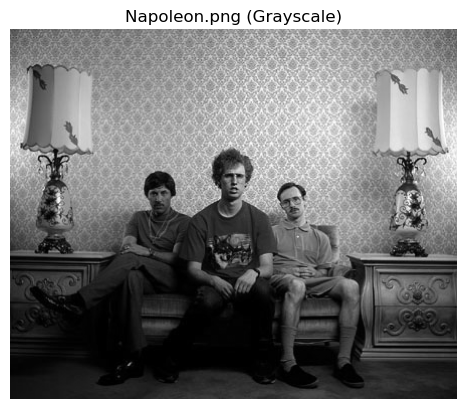

In [5]:
import matplotlib.pyplot as plt
plt.imshow(I, cmap='gray')
plt.title('Napoleon.png (Grayscale)')
plt.axis('off')            # Hide axis ticks
plt.show()

The above will show the image `I` in a new figure. We use `cmap='gray'` to display a grayscale image with its actual intensity values. Matplotlib preserves the aspect ratio by default (so circles stay circular). We can also add a color bar to visualize the intensity scale:

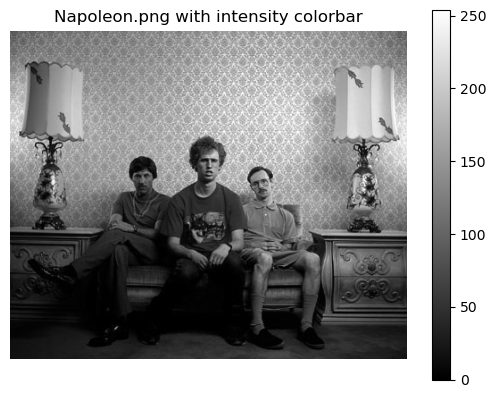

In [6]:
plt.imshow(I, cmap='gray')
plt.colorbar()
plt.title('Napoleon.png with intensity colorbar')
plt.axis('off')            # Hide axis ticks
plt.show()

#### Q1. Where in the image is the pixel (1,1) located and what is the graylevel value? In the Python environment, verify this by checking `I[0,0]` (remember that in python indexing convention, all lists/array start indexing at 0).

**A1**: 

In [7]:
#A1
# print(I[:,0])
I[0,0]

np.uint8(89)

# A1
Picture seems to start at the top left as I[0,0] = 89, printing the whole column makes this clear. 

**Saving images/figures:**
To save an image array `I` (e.g., after processing), use `cv2.imwrite('my_image.png', I)`. This writes the pixel data to a file. Example:

In [8]:
cv2.imwrite('images/my_napoleon.png', I)  # Save image I to disk

True

To save a Matplotlib figure (with overlays like colorbar), use `plt.savefig('fig.png')` on the current figure before closing it. For example:

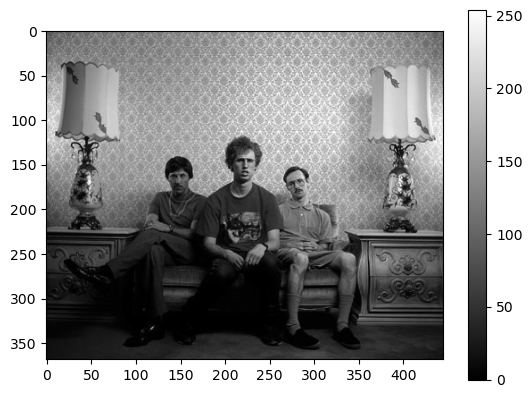

In [12]:
plt.imshow(I, cmap='gray'); 
plt.colorbar()
plt.savefig('images/nap_fig.png')

This will save the current figure as `nap_fig.png`. Make sure to call `plt.savefig` before `plt.show()`, or explicitly create a figure object to save, because after `plt.show()` in some environments the figure may be cleared.

# 3. Contrast, Brightness, and Data Types

In this section, we explore image contrast and brightness and how they relate to the intensity histogram of an image. We will use three images: `napoleon.png` (the original), `napoleon_light.png` (a brighter version), and `napoleon_dark.png` (a darker version). We also discuss how image data types (e.g., 8-bit vs floating-point) affect arithmetic operations and display.

First, let’s load the three Napoleon images and display their histograms. In Python, we can use NumPy/Matplotlib to compute and plot histograms of pixel intensities:

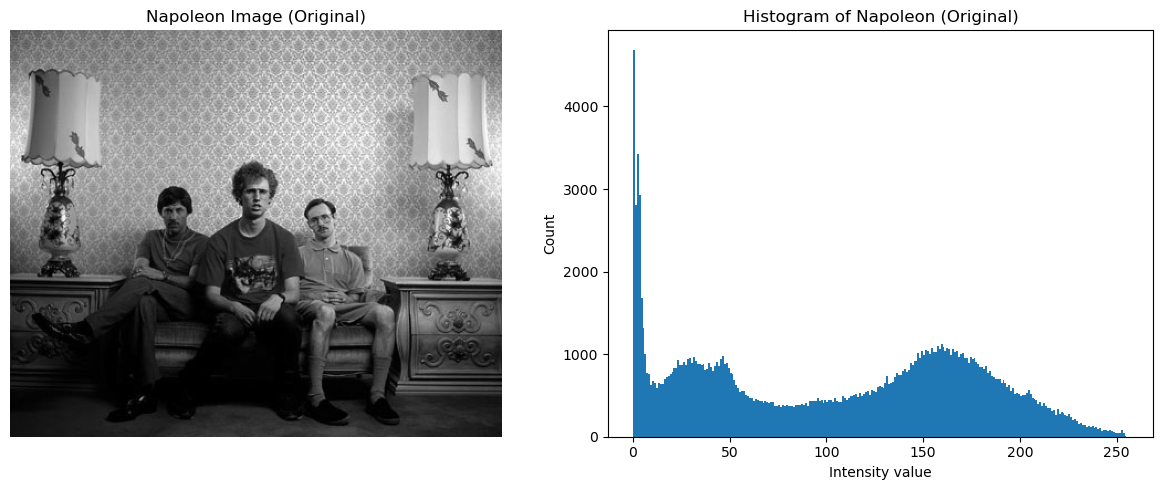

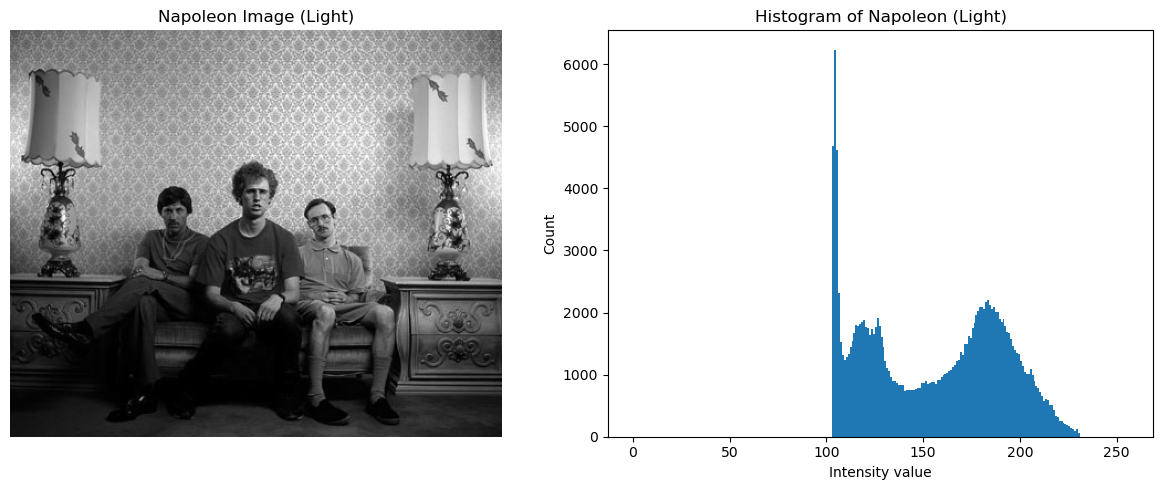

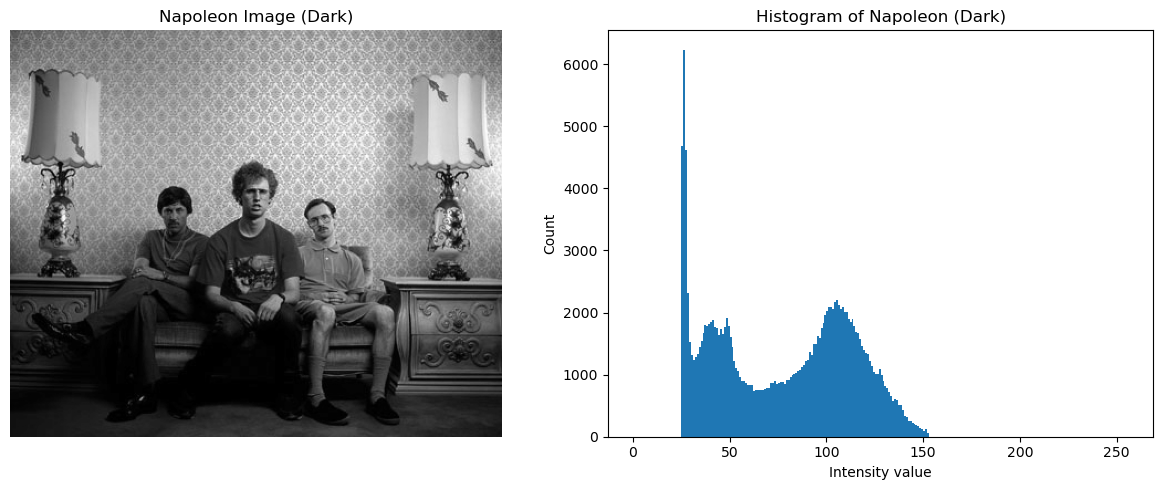

In [13]:
# Load the three images in grayscale
I_orig = cv2.imread('images/napoleon.png', cv2.IMREAD_GRAYSCALE)
I_light = cv2.imread('images/napoleon_light.png', cv2.IMREAD_GRAYSCALE)
I_dark = cv2.imread('images/napoleon_dark.png', cv2.IMREAD_GRAYSCALE)

# Create a list of images with their titles
images = [('Original', I_orig), ('Light', I_light), ('Dark', I_dark)]

# Plot histogram and image side by side for each version
for title, img in images:
    # Create a figure with 2 subplots side by side
    plt.figure(figsize=(12, 5))
    
    # First subplot: Display the grayscale image
    plt.subplot(1, 2, 1)
    plt.imshow(img, cmap='gray')
    plt.title(f"Napoleon Image ({title})")
    plt.axis('off')  # Hide the axis
    
    # Second subplot: Display the histogram
    plt.subplot(1, 2, 2)
    plt.hist(img.ravel(), bins=256, range=(0, 256))
    plt.title(f"Histogram of Napoleon ({title})")
    plt.xlabel('Intensity value')
    plt.ylabel('Count')
    
    # Adjust spacing between subplots
    plt.tight_layout()
    plt.show()

You will see that while histograms show very different distributions of pixels' intensities, images displayed are very similar to each other. This happens because the default behavior of `plt.imshow` automatically rescales data to the range of a colormap used for visualization. We can override this by explicitly specifying the minimum and maximum data values to be mapped to minimum and maximum value in the colormap with `vmin=0,vmax=255` parameters:

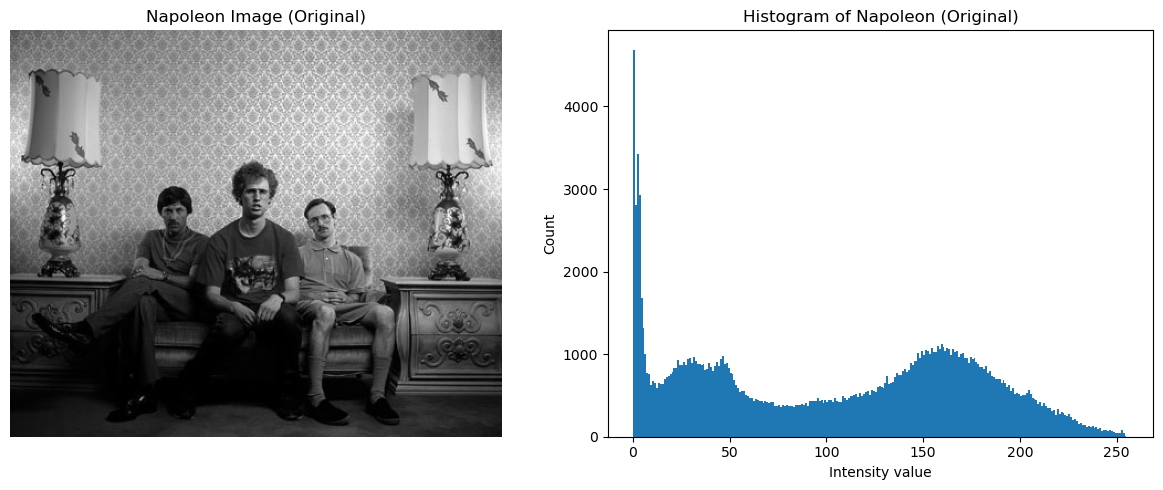

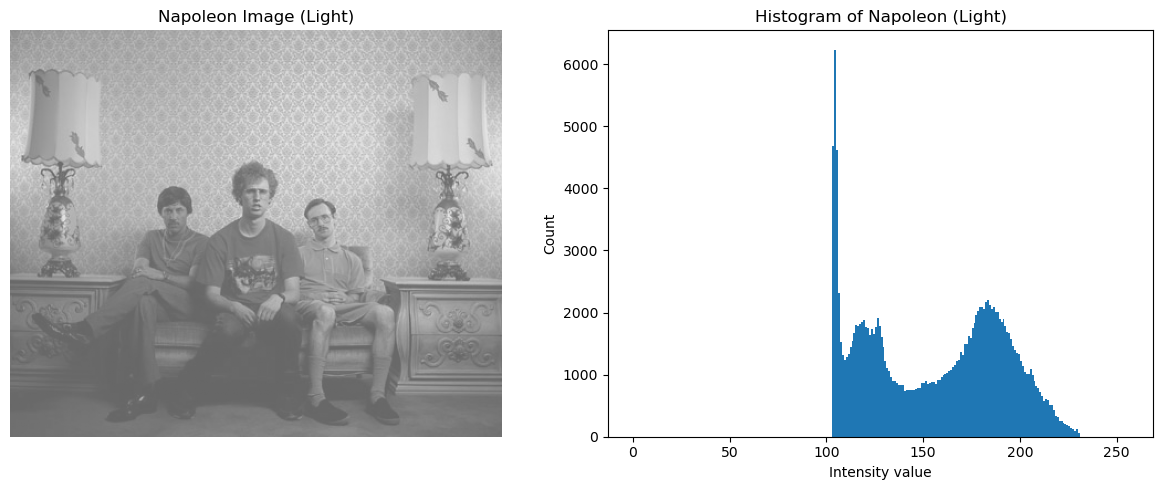

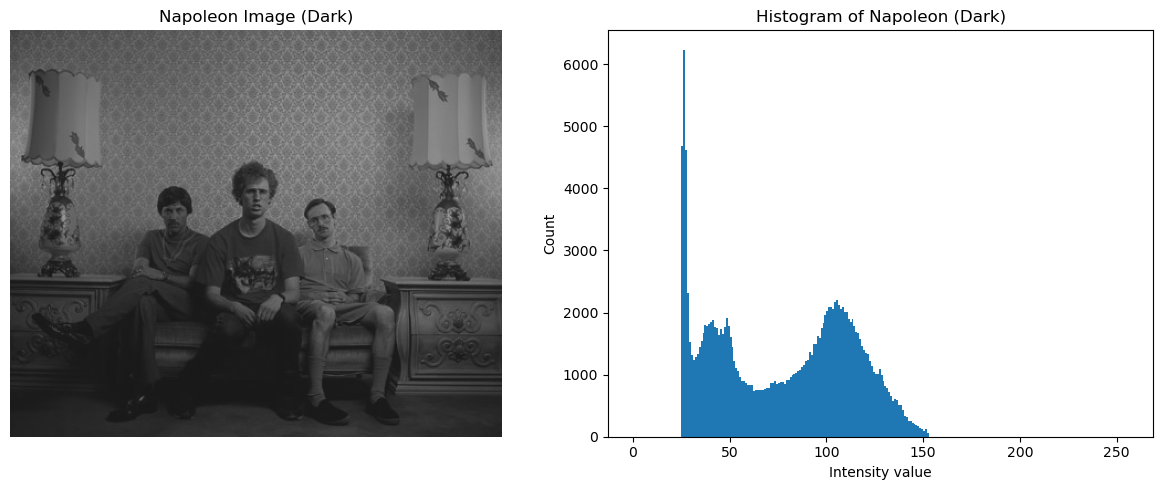

In [14]:
# Load the three images in grayscale
I_orig = cv2.imread('images/napoleon.png', cv2.IMREAD_GRAYSCALE)
I_light = cv2.imread('images/napoleon_light.png', cv2.IMREAD_GRAYSCALE)
I_dark = cv2.imread('images/napoleon_dark.png', cv2.IMREAD_GRAYSCALE)

# Create a list of images with their titles
images = [('Original', I_orig), ('Light', I_light), ('Dark', I_dark)]

# Plot histogram and image side by side for each version
for title, img in images:
    # Create a figure with 2 subplots side by side
    plt.figure(figsize=(12, 5))
    
    # First subplot: Display the grayscale image
    plt.subplot(1, 2, 1)
    plt.imshow(img, cmap='gray',vmin=0,vmax=255)
    plt.title(f"Napoleon Image ({title})")
    plt.axis('off')  # Hide the axis
    
    # Second subplot: Display the histogram
    plt.subplot(1, 2, 2)
    plt.hist(img.ravel(), bins=256, range=(0, 256))
    plt.title(f"Histogram of Napoleon ({title})")
    plt.xlabel('Intensity value')
    plt.ylabel('Count')
    
    # Adjust spacing between subplots
    plt.tight_layout()
    plt.show()

#### Q2. Explain what contrast and brightness are both in natural language and what does it mean for the numerical pixel intensities. Based on the histograms of the images `napoleon.png`, `napoleon_light.png`, and `napoleon_dark.png`,  can you tell from the histograms which image has the highest contrast and which image is the brightest?

**A2**:


high contrast is the picture with the largest difference in pixel values. brightness correlates to the largest amount of pixels with high intensity values in general. 

You see a large difference between objets and sharper edges for a high contrast piture. For a bright picture the picture is more white. 

By default, images are saved and loaded as `uint8` (0–255), which contains only integer values. Many mathematical operations (for example division) in python will automatically convert the data type into `float`. Matplotlib is fully compatible with `float` images  and will automatically scale it to colormap colors, but be careful if you save and reload your image, which will lose the floating-point precision.
For example, consider our original image `I_orig`. First, we will create a floating-point copy of it by dividing all pixel intensities by 64 and multiplying it by 64. Second, we will do the same operations, but save the intermediate result to file and reload it:

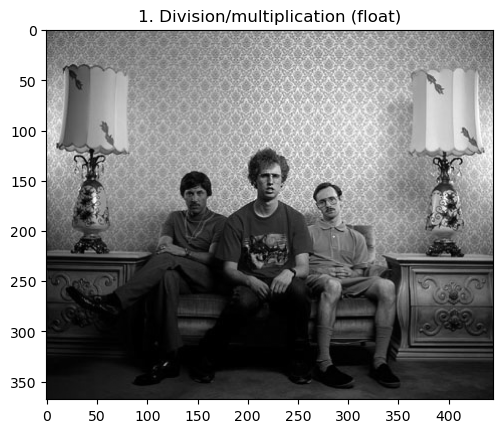

[ WARN:0@553.076] global loadsave.cpp:1089 imwrite_ Unsupported depth image for selected encoder is fallbacked to CV_8U.


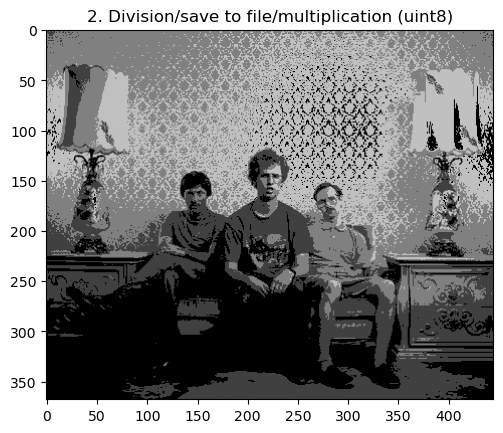

In [15]:
plt.imshow( I_orig/64*64, cmap='gray',vmin=0,vmax=255); plt.title('1. Division/multiplication (float)'); plt.show()
cv2.imwrite('images/my_napoleon_div64.png', I_orig/64)
I_div64 = cv2.imread('images/my_napoleon_div64.png', cv2.IMREAD_GRAYSCALE)*64
plt.imshow(I_div64, cmap='gray',vmin=0,vmax=255); plt.title('2. Division/save to file/multiplication (uint8)'); plt.show()

Note: You can explicitly convert NumPy array objects (data type that we use to store images in examples above) to different types by calling method `astype`. For example `I_orig.astype('float')` would return floating-point version of `I_orig` and `(I_orig/64).astype('uint8')` would return (0-255) version of `I_orig/64`

#### Q3. Explain the difference between two images above. What has happened to pixel data after saving and reloading intermediate calculation results as an image? Hint: Use histograms for easier analysis.

**A3**. 

In [ ]:
#A3
# When saving the piture, it rounds the pixel vaules to the nearest integer. 
# This collapses the picture into only a few disticnt pixel values. Multiplying by 64 then only amplifies 
# these values but more distinct values cannot be recreated.

# not saving and reloading, avoids this rounding and keeps the floating number meaning this rounding error does not 
# appear. Every number can then be recreated again when multiplying with 64. 


#### Q4. Demonstrate a mathematical expression involving `I_orig` to make it brighter. Remember to use `vmin=0,vmax=255` parameters or matplotlib will automatically rescale your image.

**A4**.

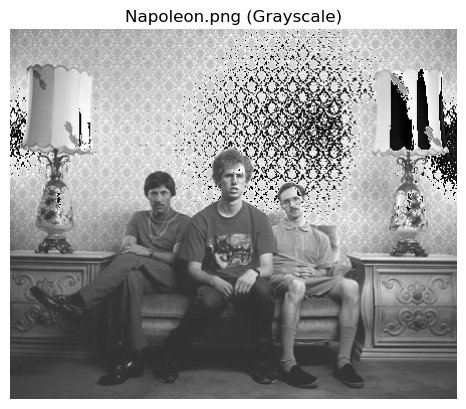

In [21]:
#A4
plt.imshow(I+50, cmap='gray',vmin=0,vmax=255)
plt.title('Napoleon.png (Grayscale)')
plt.axis('off')            
plt.show()

#Add a constant makes it brigther

# For some reason it matplotlib seems to use //255 when some pixel values are larger than 255 resulting in black spots 
# where the picture previously was white 
# This setting could probabily be changed if it is wanted

#### Q5. Demonstrate a mathematical expression involving `I_orig` to give it lower contrast.

**A5**. 

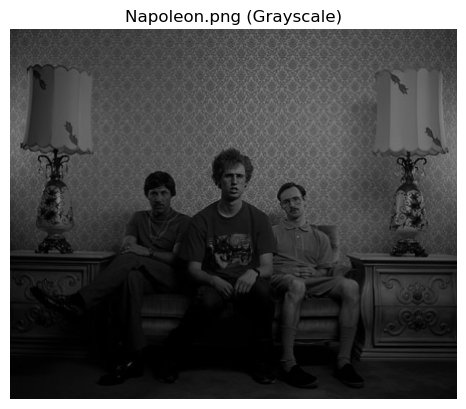

In [22]:
#A5
plt.imshow(I*0.5, cmap='gray',vmin=0,vmax=255)
plt.title('Napoleon.png (Grayscale)')
plt.axis('off')            
plt.show()

#Multiply by a constant lower than 1

# 4. Pixelwise Transforms

Most of mathematical operations applied to numerical arrays in python will be applied pixel-wise, as we have already seen with multiplication and division. One common point transform is the gamma correction (or power-law transform): $ output\_pixel = C * (input\_pixel)^\gamma $. Typically we first normalize the input to $[0,1]$, apply power $\gamma$, then scale back to 0–255:

`
I2 = (I_orig/255)**gamma * 255
`

#### Q6. Use $\gamma=2$ and $\gamma=0.5$ and explain the resulting images.

**A6**. 

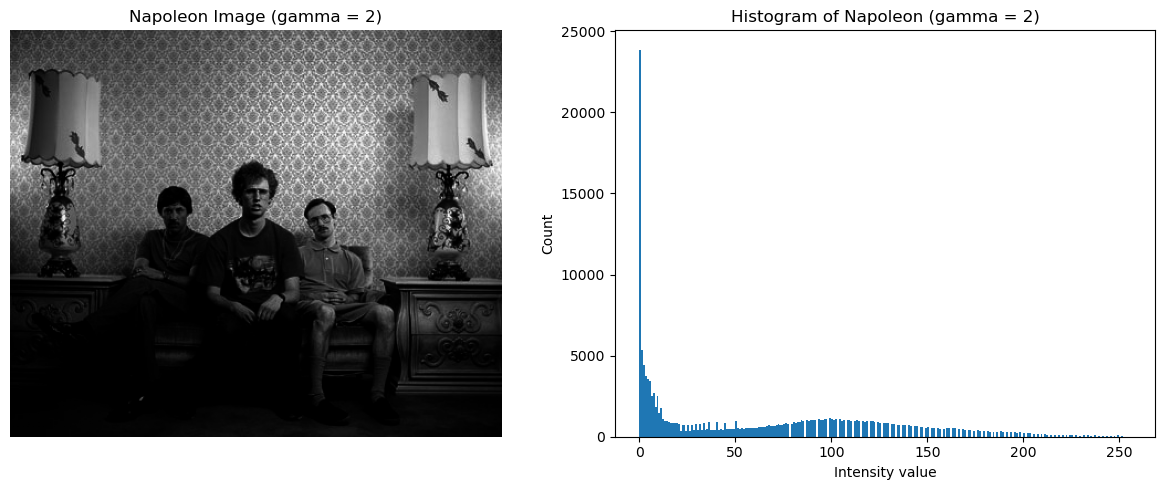

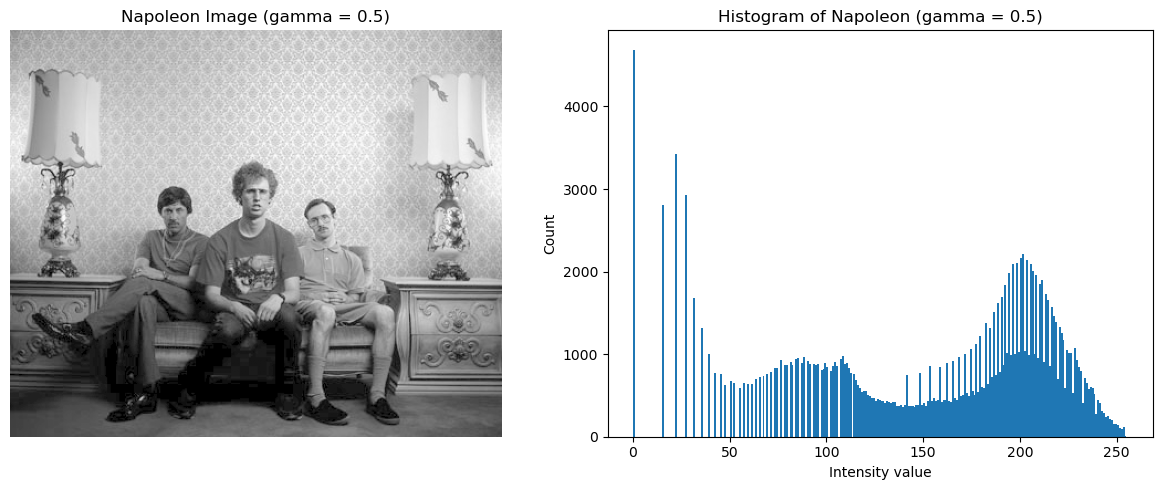

In [23]:
gamma_1 = 2
gamma_2 = 0.5
I2 = (I_orig/255)**gamma_1 * 255
I3 = (I_orig/255)**gamma_2 * 255

images = [('gamma = 2', I2), ('gamma = 0.5', I3)]

# Plot histogram and image side by side for each version
for title, img in images:
    # Create a figure with 2 subplots side by side
    plt.figure(figsize=(12, 5))
    
    # First subplot: Display the grayscale image
    plt.subplot(1, 2, 1)
    plt.imshow(img, cmap='gray',vmin=0,vmax=255)
    plt.title(f"Napoleon Image ({title})")
    plt.axis('off')  # Hide the axis
    
    # Second subplot: Display the histogram
    plt.subplot(1, 2, 2)
    plt.hist(img.ravel(), bins=256, range=(0, 256))
    plt.title(f"Histogram of Napoleon ({title})")
    plt.xlabel('Intensity value')
    plt.ylabel('Count')
    
    # Adjust spacing between subplots
    plt.tight_layout()
    plt.show()

With lower gamma, we get get higher contrast and higher brightness, while the higher gamma yields lower contrast and lower brightness.

Histogram equalization is also a pixelwise graylevel transformation. It can be applied to an image using `I_eq = cv2.equalizeHist(I)` operation.

#### Q7. Explain how histogram equalization works in theory. Include histograms of one of the images (dark or light) before and after applying equalization, and explain what you see. Do the changes to the histograms and the images agree with the theory of histogram equalization?

**A7**. 

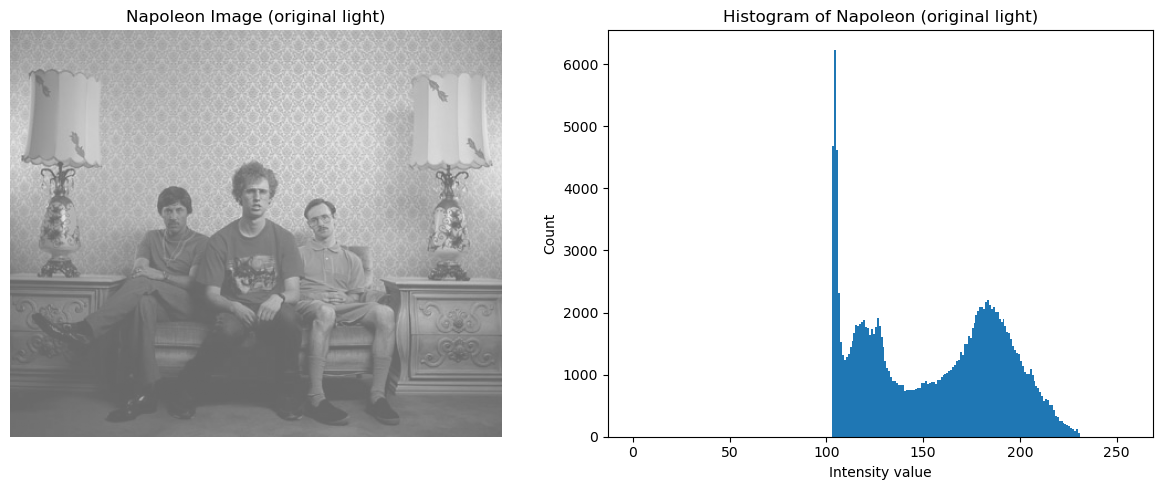

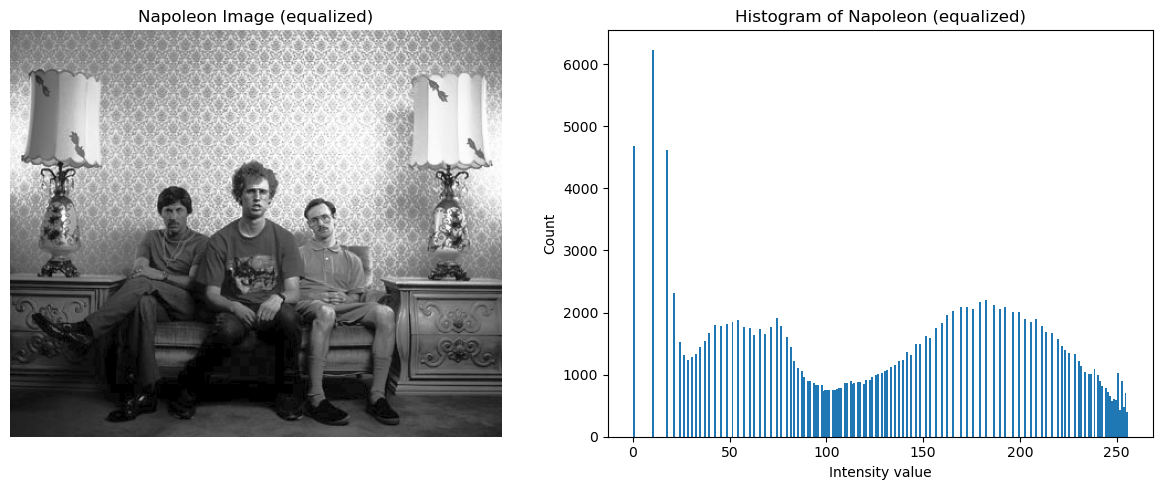

In [24]:
#A7
I_eq = cv2.equalizeHist(I_light)
images = [('original light', I_light), ('equalized', I_eq)]
# Plot histogram and image side by side for each version
for title, img in images:
    # Create a figure with 2 subplots side by side
    plt.figure(figsize=(12, 5))
    
    # First subplot: Display the grayscale image
    plt.subplot(1, 2, 1)
    plt.imshow(img, cmap='gray',vmin=0,vmax=255)
    plt.title(f"Napoleon Image ({title})")
    plt.axis('off')  # Hide the axis
    
    # Second subplot: Display the histogram
    plt.subplot(1, 2, 2)
    plt.hist(img.ravel(), bins=256, range=(0, 256))
    plt.title(f"Histogram of Napoleon ({title})")
    plt.xlabel('Intensity value')
    plt.ylabel('Count')
    
    # Adjust spacing between subplots
    plt.tight_layout()
    plt.show()


In theory, histogram equalization works by mapping the pixel intensities so the histogram becomes as flat as possible, which spreads the used intensity range and increases contrast.

It maximizes the contrast given the pixel values by mapping the intensity values to the range (0,255) so a larger range of integers are used which is clear in for the image above. 

# 5. Aliasing when Sampling

When we resample or resize images, improper handling can introduce aliasing – artifacts that occur when high-frequency detail is undersampled. The lab uses an image of a zebra (with high-frequency stripe pattern) and the classic `cameraman.png` as examples. Try to downsample these images to a smaller size (78×78 pixels) using different interpolation methods and with/without anti-aliasing (low-pass filtering) to see the effects.

An easy way to resize an image in python is using `cv2.resize` function like `I_resized = cv2.resize(I, (78, 78), interpolation=cv2.INTER_NEAREST)` or `I_resized = cv2.resize(I, (78, 78), interpolation=cv2.INTER_LINEAR)`. You may look up for other available methods in OpenCV documentation.

When applied to images with regular high-frequency patterns, resizing may create aliasing artifacts. To compensate for this, we may attempt to apply low-pass filter prior to resizing, which reduces/removes higher frequencies from an image. One simple way to do this is with Gaussian filtering:
`I_filtered = cv2.GaussianBlur(I, (7,7), 0)`

Note: Default matplotlib `imshow()` behavior will resize any image to default figure size. If you want to fix on-screen pixel size to see images in fixed resolution, you may explicitly control figure size like this:<br>
`dpi = 100`<br>
`fig = plt.figure(figsize=(I.shape[0]/dpi, I.shape[1]/dpi))`<br>
`plt.imshow( I, cmap='gray',vmin=0,vmax=255); plt.show()`

#### Q8. Explain the role of the interpolation method as well as the role of the lowpass filter (anti-aliasing). Which combination of options do you prefer, and why?

**A8** 


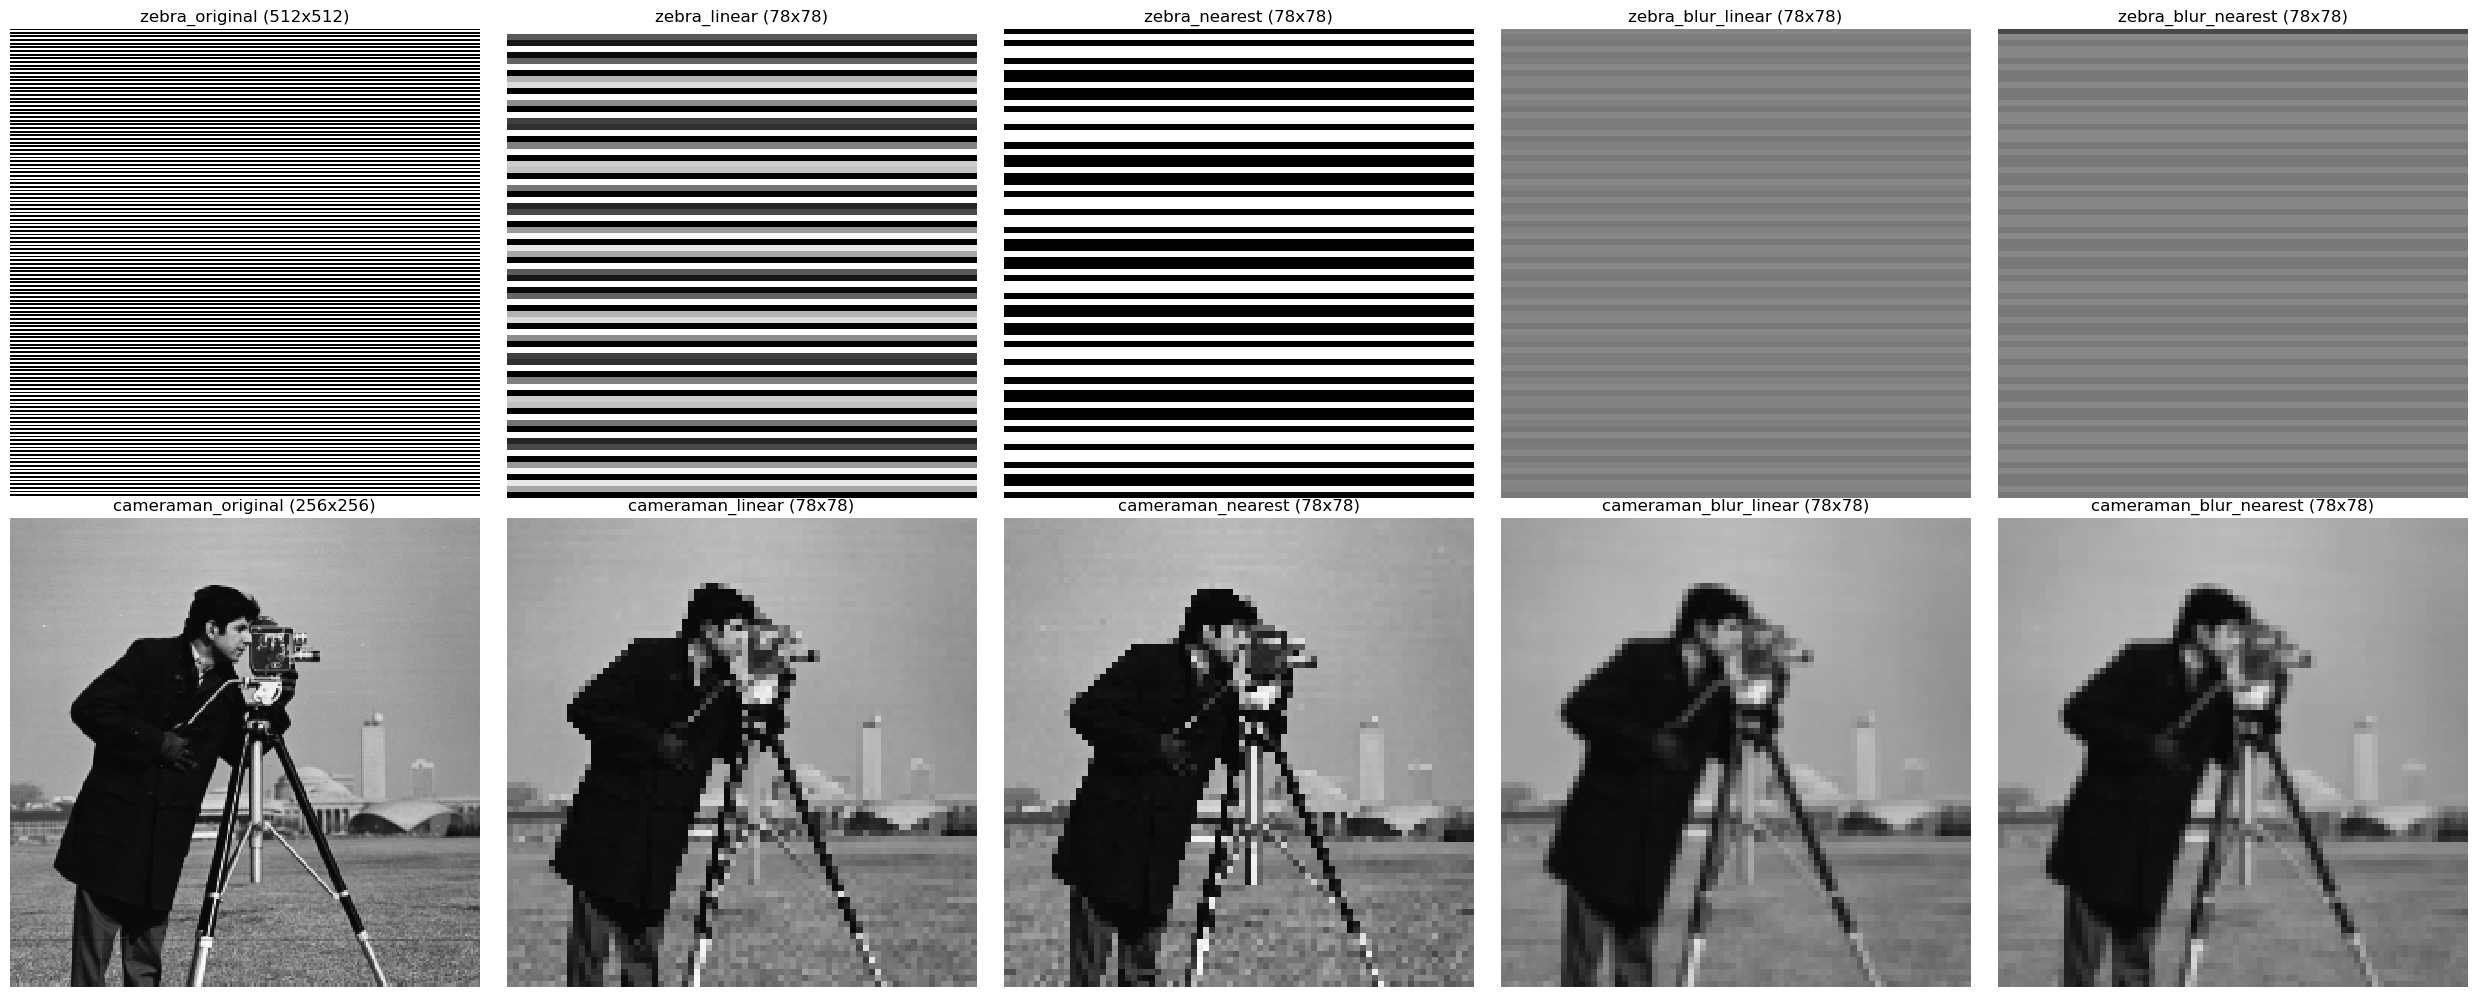

In [25]:
#A8
I_zebra = cv2.imread('images/zebra.png', cv2.IMREAD_GRAYSCALE)
I_cameraman = cv2.imread('images/cameraman.png', cv2.IMREAD_GRAYSCALE)

# Without anti-aliasing
I_zebra_resized_linear = cv2.resize(I_zebra, (78, 78), interpolation=cv2.INTER_LINEAR)
I_zebra_resized_nearest = cv2.resize(I_zebra, (78, 78), interpolation=cv2.INTER_NEAREST)

I_cameraman_resized_linear = cv2.resize(I_cameraman, (78, 78), interpolation=cv2.INTER_LINEAR)
I_cameraman_resized_nearest = cv2.resize(I_cameraman, (78, 78), interpolation=cv2.INTER_NEAREST)

# With anti-aliasing (Gaussian low-pass filter before resizing)
I_zebra_blur = cv2.GaussianBlur(I_zebra, (7, 7), 0)
I_cameraman_blur = cv2.GaussianBlur(I_cameraman, (7, 7), 0)

I_zebra_blur_linear = cv2.resize(I_zebra_blur, (78, 78), interpolation=cv2.INTER_LINEAR)
I_zebra_blur_nearest = cv2.resize(I_zebra_blur, (78, 78), interpolation=cv2.INTER_NEAREST)

I_cameraman_blur_linear = cv2.resize(I_cameraman_blur, (78, 78), interpolation=cv2.INTER_LINEAR)
I_cameraman_blur_nearest = cv2.resize(I_cameraman_blur, (78, 78), interpolation=cv2.INTER_NEAREST)

images = [('zebra_original', I_zebra), ('zebra_linear', I_zebra_resized_linear), ('zebra_nearest', I_zebra_resized_nearest),
          ('zebra_blur_linear', I_zebra_blur_linear), ('zebra_blur_nearest', I_zebra_blur_nearest),
          ('cameraman_original', I_cameraman), ('cameraman_linear', I_cameraman_resized_linear), ('cameraman_nearest', I_cameraman_resized_nearest),
          ('cameraman_blur_linear', I_cameraman_blur_linear), ('cameraman_blur_nearest', I_cameraman_blur_nearest)]

plt.figure(figsize=(25, 10))
for i, (title, I) in enumerate(images):
    plt.subplot(2, 5, i + 1)
    plt.imshow(I, cmap='gray', vmin=0, vmax=255, interpolation='nearest')
    plt.title(f"{title} ({I.shape[1]}x{I.shape[0]})")
    plt.axis('off')
plt.tight_layout()
plt.show()

Linear interpolation uses several of the closest picture to determine the value of a certain pixel while nearest only uses the closest pixel. In the zebra picture, there are finer details and therefore aliasing occurs. The pattern goes from being ordered, to a somewhat random pattern.

Aliasing happens when the image has details finer than the new pixel grid can represent.
The filter removes the highest contrasts in the pictures which will not pass through the interpolation. 

Gaussian blur removes aliasing and gives quite smooth results. It is better in the cameraman picture which does not contain as many fine details. All the interpolations and antialiasing filters, 
work quite bad in the zebra case because it consists solely of fine details.

#### Q9. Can you give a real-life example of aliasing outside the area of image analysis and signal processing in general? Have you seen this phenomenon before?

# A9
When looking at a car driving, sometimes it looks like the wheels are turning backwards slowly while the car is driving forward. This is because of the eye samples at a frequency resulting in aliasing.

# 6. Image Arithmetic

A SPECT image shows the activity in the brain. When evaluating patient data it is often of interest to 
make a comparison with an image of a “standard” healthy brain. Standard data is created by averagin 
over a large number of images of healthy brains. The difference between the standard data and the
patient data is found by subtracti
on.
Images brain1.png and brain2.png show two SPECT images of healthy brains. Image brain3 png
shows a SPECT image of a brain from a patient with a stroke.


#### Q10. How can a “standard” healthy brain, or a mean image, of the two images brain1.png and brain2.png be constructed? Include a figure showing the standard brain.

Taking the difference between the mean of healthy brains and the unhealthy makes the unhealthy brain stand out.

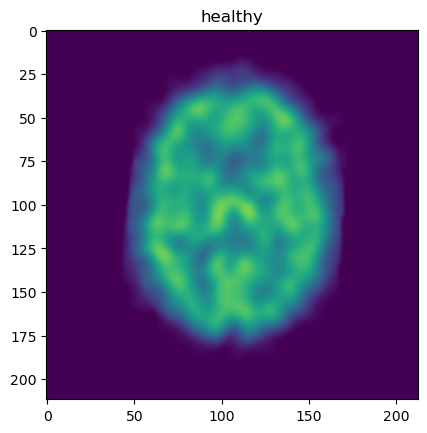

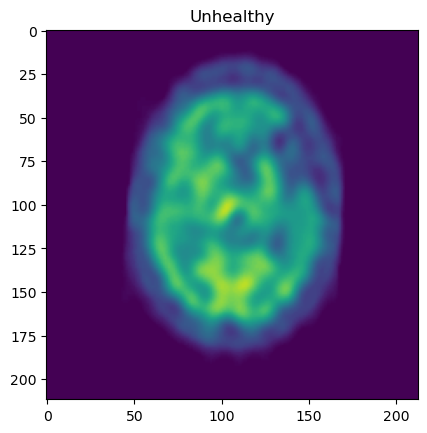

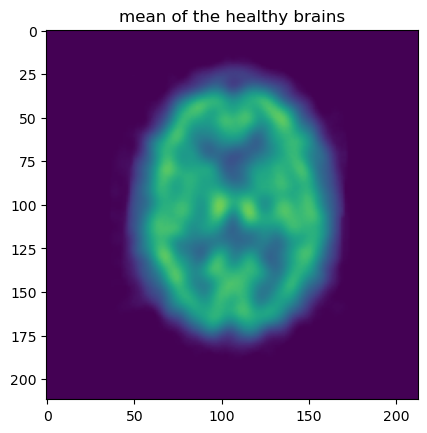

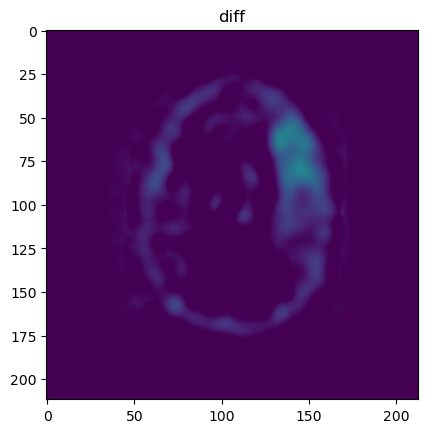

In [26]:
#A10
b1 = cv2.imread('images/brain1.png', cv2.IMREAD_GRAYSCALE).astype(float)
b2 = cv2.imread('images/brain2.png', cv2.IMREAD_GRAYSCALE).astype(float)
b3 = cv2.imread('images/brain3.png', cv2.IMREAD_GRAYSCALE).astype(float)

standard = (b1/2+b2/2)

plt.figure(1)
plt.title('healthy')
plt.imshow(b1, vmin=0,vmax=255)
plt.figure(2)
plt.title('Unhealthy')
plt.imshow(b3, vmin=0,vmax=255)
plt.figure(3)
plt.title('mean of the healthy brains')
plt.imshow(standard, vmin=0,vmax=255)

plt.figure(4)
plt.title('diff')
diff = standard - b3
plt.imshow(diff, vmin=0,vmax=255)


#### Q11. Find the difference between the “standard” brain and the image from the stroke patient (brain3.png). Where in the brain is the change located?

In [ ]:
#A11
#Unhealthy brain has lower activity in the uppper right part 

#### Q12. What happens if the pixel values of uint8 images go below 0 or above 255? Did you think of this when you computed the "“standar"” brain in the previous exercise Visualize an image which would contain uint8 overflow artifacts. ?

In [ ]:
#A12
# When taking the average we should divide by the number of piture before adding them toghether to avoid overflow.
# It is only when the picture is saved that the rounding occurs so it should not matter if intermediate results overflow. 

# When taking an average of 2 number between 0 and 255, the result cannot will also always be in range(0,255)

In [ ]:
import numpy as np
a = np.array([200], dtype=np.uint8)
b = np.array([100], dtype=np.uint8)

print("a + b                         =", a + b)
print("(a + b) / 2                   =", (a + b) / 2)
print("(a.astype(float) + b) / 2     =", (a.astype(float) + b) / 2)

a + b                         = [44]
(a + b) / 2                   = [22.]
(a.astype(float) + b) / 2     = [150.]


# 7. Geometric Transforms

It is sometimes necessary to geometrically correct images. In object recognition a first step can be to rotate the image so that the object is in a standard position, for example along the vertical axis. Open the image wrench.png and rotate it 20 degrees, with and without interpolation.

Hint:
Use PIL package `Image` class for simple rotation methods. You may load PIL `Image` from file:
`wrench_img = Image.open('lab1/images/wrench.png')`
or you can convert our NumPy arrays into PIL image:
`img = Image.fromarray(I)`

For rotation, use this function:

`# without interpolation (nearest)`

`img_nearest = img.rotate(20, resample=Image.NEAREST, expand=False)`

`# with bilinear interpolation`

`img_bilinear = img.rotate(20, resample=Image.BILINEAR, expand=False)`

#### Q13. Compare rotations performed with and without interpolation. It is easiest to see differences along lines and edges of the images. What does interpolation mean in this case?

**A13**:

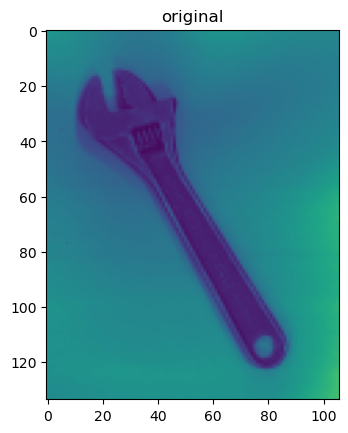

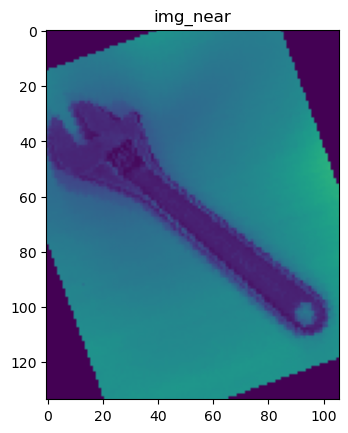

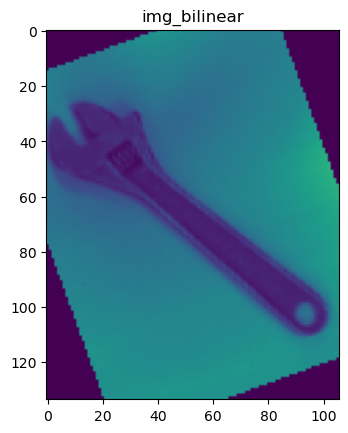

In [28]:
#A13
from PIL import Image
wrench_img = Image.open('images/wrench.png')
# img = Image.fromarray(wrench_img)
# without interpolation (nearest)

img_nearest = wrench_img.rotate(20, resample=Image.NEAREST, expand=False)

# with bilinear interpolation

img_bilinear = wrench_img.rotate(20, resample=Image.BILINEAR, expand=False)

plt.figure(0)
plt.title('original')
plt.imshow(wrench_img, vmin=0,vmax=255)

plt.figure(1)
plt.title('img_near')
plt.imshow(img_nearest, vmin=0,vmax=255)

plt.figure(2)
plt.title('img_bilinear')
plt.imshow(img_bilinear, vmin=0,vmax=255)

Bilinear takes the average of several pixels close to the wanted position while nearest only uses one leading to worse resolution.

#### Q14. In general it is faster to rotate the image by a multiple of 90 degrees than by some arbitrary degree. Explain why. For this task use `time.time()` function from `time` module.

**A14**: Rotating 90 degrees just moves each pixel to a new pixel position, so no interpolations are needed. Rotating by another angle (e.g. 20 degrees) requires computing new positions with sin/cos for every pixel, and these positions usually fall between pixels, so the values must be interpolated. This takes more time.

In [42]:
#A14
import time
from PIL import Image

img = Image.open('images/wrench.png')
img.load()

start = time.perf_counter()
img.rotate(90, resample=Image.BILINEAR, expand=True)
print(f"90 degrees: {time.perf_counter() - start:.7f}")

start = time.perf_counter()
img.rotate(20, resample=Image.BILINEAR, expand=True)
print(f"20 degrees: {time.perf_counter() - start:.7f}")

90 degrees: 0.0000950
20 degrees: 0.0003565


# 8. Scripting and Looping

#### Q15 Write a script performing the following steps on a random image (download one from Internet):
* Load the image.
* Convert the image to grayscale (if not already) using e.g. rgb2gray.
* Resize and/or crop the image to 128×128 pixels, without changing the aspect ratio of the image.
* Loop over the image using a 5×5 pixel window. For each such window, compute the average pixel value and store it in a new image. Treat borders in some controlled way and make sure the result has the same size as the original image. (This will require nested loops to scan rows and columns.)
* Subtract the original image from your new filtered image.
* Present the original, filtered, and subtracted images in a figure, using e.g. subplot.

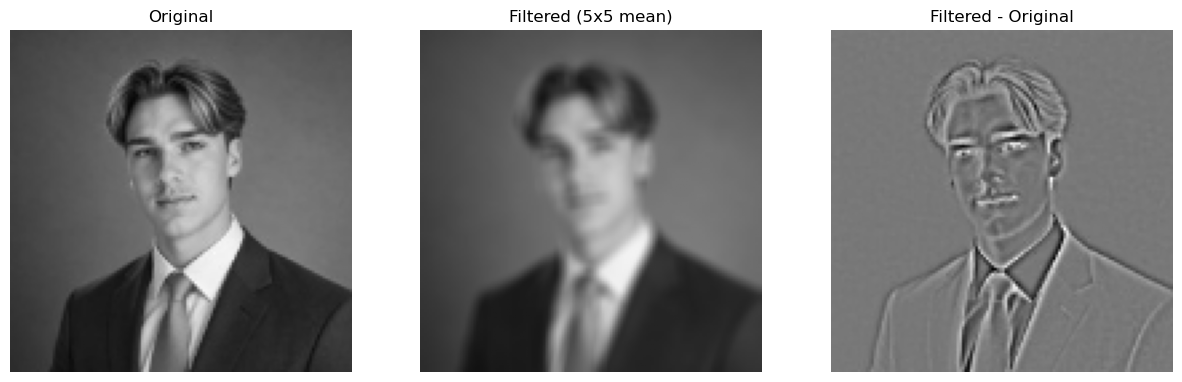

In [44]:
#A15
import numpy as np

I = cv2.imread('images/bilip.png')
I = cv2.cvtColor(I, cv2.COLOR_BGR2GRAY)

I = cv2.resize(I, (128, 128)).astype(float)

# 5x5 mean filter
# Padded with the closest edge value
padded = np.pad(I, 2, mode='edge')
filtered = np.zeros_like(I)
for r in range(128):
    for c in range(128):
        filtered[r, c] = padded[r:r+5, c:c+5].mean()

# Subtract the original image
diff = filtered - I

plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1); plt.imshow(I, cmap='gray', vmin=0, vmax=255); plt.title('Original'); plt.axis('off')
plt.subplot(1, 3, 2); plt.imshow(filtered, cmap='gray', vmin=0, vmax=255); plt.title('Filtered (5x5 mean)'); plt.axis('off')
plt.subplot(1, 3, 3); plt.imshow(diff, cmap='gray'); plt.title('Filtered - Original'); plt.axis('off')
plt.show()

#### Q16 Write a script performing the following steps on a random image (download one from Internet):
* Load the image.
* Convert the image to grayscale if needed.
* Perform histogram equalization on this image using your own algorithm, without using `cv2.equalizeHist`. Efficiency is not important; you may use for-loops or other methods to compute the transformation and apply it.
* Present the original and equalized images in a figure. Compare with OpenCV native `cv2.equalizeHist` function.
* Make your own histogram equalization into a callable function (e.g. `Inew = myhist(I)`) and include the code in the report.

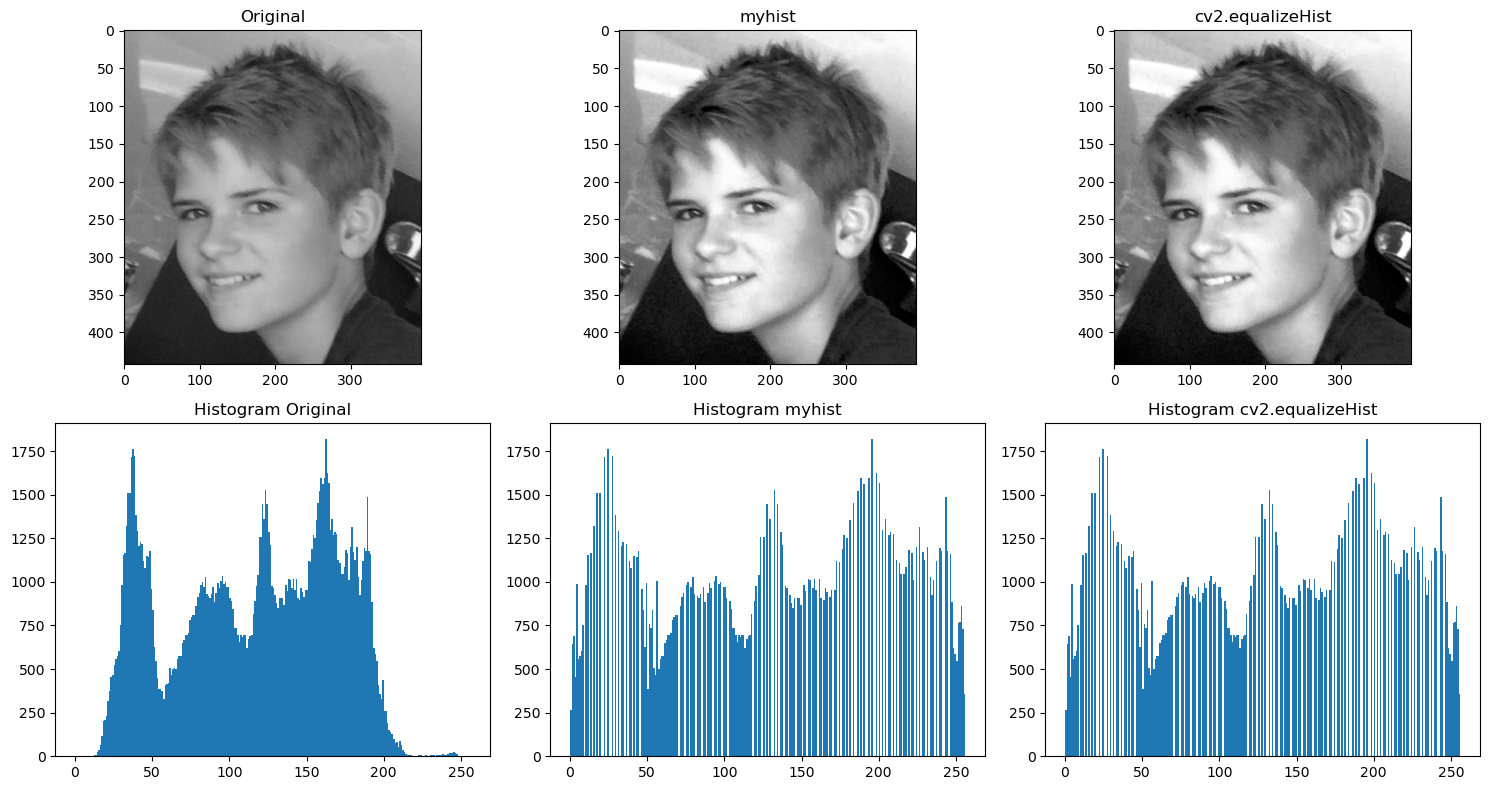

In [ ]:
#A16
import numpy as np

def myhist(I):
    # Count how many pixels have each gray level (0-255)
    hist = np.zeros(256)
    for value in I.ravel():
        hist[value] += 1
    # create cumulative histogram
    cdf = np.cumsum(hist)
    # Normalize to 0-1 and then mult with 255 to maximize number of used intensities
    # Index of cdf is now the old intensity and the value is a new intensity with all both 0 and 255 used.
    cdf = (cdf - cdf[I.min()]) / (cdf[-1] - cdf[I.min()]) * 255
    result = np.zeros_like(I)
    rows, cols = I.shape
    for r in range(rows):
        for c in range(cols):
            result[r, c] = np.round(cdf[I[r, c]])
    return result

I = cv2.imread('images/boel.png', cv2.IMREAD_GRAYSCALE)

images = [('Original', I), ('myhist', myhist(I)), ('cv2.equalizeHist', cv2.equalizeHist(I))]

plt.figure(figsize=(15, 8))
for i, (title, img) in enumerate(images):
    plt.subplot(2, 3, i + 1); plt.imshow(img, cmap='gray', vmin=0, vmax=255); plt.title(title)
    plt.subplot(2, 3, i + 4); plt.hist(img.ravel(), bins=256, range=(0, 256)); plt.title(f'Histogram {title}')
plt.tight_layout()
plt.show()

**A16**: Our function `myhist` first counts how many pixels have each gray level (the histogram). It then computes the cumulative histogram. This is normalized to the range 0–255 and used as a lookup table, so each pixel gets a new value based on how many pixels are darker than it.

The original image only uses gray levels between roughly 15 and 210, with most pixels in a few peaks. After equalization the histogram is spread out over the whole range 0–255, which gives higher contrast, dark areas become darker and bright areas brighter.

Our histogram seems to give the same result as cv2.equalizeHist. The histograms are not completely flat because pixels with the same gray level always gets mapped to the same new value, so the counts per bar cannot be split to different levels. As some intensities are not present, and some probabily gets mapped to the same new intensity, some gray levels are not used, which explains the gaps in between the bars in the histogram above.